<a href="https://colab.research.google.com/github/wengua326/data-science-toolkit/blob/main/tutorial3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('/content/drive/MyDrive/train.csv')
display(df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


2&4. Evaluate if the data is good or not. Does it have enough samples?

In [8]:
print("Row and Column :", df.shape)
print("Number of duplicate :", df["Name"].duplicated().sum())
print("Number of Survivor :", df['Survived'].value_counts())

Row and Column : (891, 12)
Number of duplicate : 0
Number of Survivor : Survived
0    549
1    342
Name: count, dtype: int64


3. How many features does it have? Is it enough?

In [12]:
print("All column :", df.columns.tolist())
print("Number of columns are", len(df.columns))
print("Number of feature (exclude survivor) are", len(df.columns)-1)

All column : ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Number of columns are 12
Number of feature (exclude survivor) are 11


5. What are the datatypes does the dataset consist of?

In [15]:
print("The datatype are", df.dtypes.tolist())


The datatype are [dtype('int64'), dtype('int64'), dtype('int64'), dtype('O'), dtype('O'), dtype('float64'), dtype('int64'), dtype('int64'), dtype('O'), dtype('float64'), dtype('O'), dtype('O')]


6&8. How many columns have null values?

In [25]:
missing = df.isnull().sum()
print(missing)
row_missing = df[df.isnull().any(axis=1)]
print(len(row_missing))
column_missing = missing[missing > 0]
print(len(column_missing))

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
708
3



7. Which column is the feature, which is the target output?

In [16]:
target="Survived"
features = df.drop(columns=["Survived", "PassengerId"])

How did survival rate differs by passenger class?

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


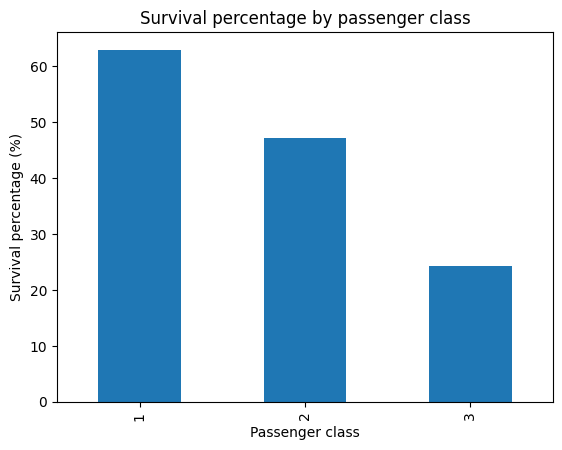

In [27]:
survival_rate = df.groupby("Pclass")["Survived"].mean() * 100
print(survival_rate.round(1))
survival_rate.plot(kind="bar")
plt.title("Survival percentage by passenger class")
plt.xlabel("Passenger class")
plt.ylabel("Survival percentage (%)")
plt.show()